# 02 - Model Training: Random Forest (UNSW-NB15)

Phát hiện tấn công dạng nhị phân (`label`: 0 = Normal, 1 = Attack) trên dữ liệu đã làm sạch ở notebook 01.

- Train trên `UNSW_NB15_training-set.parquet`, đánh giá trên `UNSW_NB15_testing-set.parquet` (tập test riêng, không dùng để train hay tinh chỉnh).
- Không dùng `label` và `attack_cat` làm feature (`attack_cat` mô tả trực tiếp loại tấn công → rò rỉ nhãn).
- Encoder chỉ fit trên tập train, sau đó áp dụng cho tập test.

In [1]:
import os

# Tự nhận diện môi trường: Colab (mount Google Drive) hoặc máy local (Google Drive for Desktop)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/5G_IDS_Project'
except ImportError:
    # Notebook nằm trong 5G_IDS_Project/notebooks -> thư mục project là thư mục cha
    BASE = os.path.abspath('..')

print("Thư mục project:", BASE)

Thư mục project: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project


In [2]:
import pandas as pd

cleaned_dir = os.path.join(BASE, 'data', 'cleaned')
models_dir = os.path.join(BASE, 'models')

train = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_training-set.parquet'))
test = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_testing-set.parquet'))

# Tách Target (y) và Features (X)
target_cols = ['label', 'attack_cat']
X_train, y_train = train.drop(columns=target_cols), train['label']
X_test, y_test = test.drop(columns=target_cols), test['label']

categorical_cols = X_train.select_dtypes(include=['category', 'object']).columns.tolist()
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Phân loại ({len(categorical_cols)}): {categorical_cols}')
print(f'Số ({len(numeric_cols)}): {numeric_cols}')
display(pd.DataFrame({'Training': y_train.value_counts(), 'Testing': y_test.value_counts()}))

Train: (98934, 31), Test: (50567, 31)
Phân loại (3): ['proto', 'service', 'state']
Số (28): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_flw_http_mthd', 'ct_src_ltm']


,Training,Testing
label,,
0,49825,32034
1,49109,18533


In [3]:
# Kiểm tra: không có cột mục tiêu và không có cột ô nhiễm nào đã bị loại ở bước làm sạch
removed_cols = ['id', 'ct_state_ttl', 'sttl', 'dttl', 'ct_dst_ltm', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_srv_ltm',
                'ct_srv_src', 'ct_dst_sport_ltm', 'is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']
assert not set(target_cols + removed_cols) & set(X_train.columns)
assert list(X_train.columns) == list(X_test.columns)
print('OK: feature set chỉ gồm các cột đã làm sạch')

OK: feature set chỉ gồm các cột đã làm sạch


## Tiền xử lý + Random Forest

- `proto`, `service`, `state` là biến định danh (không có thứ tự) → dùng **One-Hot Encoding** thay vì `LabelEncoder` (tránh tạo quan hệ thứ tự giả, vd. `tcp=113 > udp`).
- `handle_unknown='ignore'`: giá trị chỉ có trong tập test (vd. `state` = `ACC`, `CLO`) được mã hóa thành toàn 0, không gây lỗi.
- Random Forest không cần chuẩn hóa (scaling) cột số → giữ nguyên.
- Pipeline gói encoder + model, nên `fit` chỉ nhìn thấy tập train.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
], remainder='passthrough', verbose_feature_names_out=False)

model = Pipeline([
    ('preprocess', preprocess),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
])

# Chỉ fit trên tập train (encoder + model)
model.fit(X_train.astype({c: str for c in categorical_cols}), y_train)
print('Số feature sau one-hot:', len(model.named_steps['preprocess'].get_feature_names_out()))

Số feature sau one-hot: 183


In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_pred = model.predict(X_test.astype({c: str for c in categorical_cols}))

metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
}
display(pd.DataFrame(metrics, index=['Test']).round(4))
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Attack (1)'], digits=4))

,accuracy,precision,recall,f1
Test,0.8176,0.6807,0.9459,0.7917


              precision    recall  f1-score   support

  Normal (0)     0.9596    0.7433    0.8377     32034
  Attack (1)     0.6807    0.9459    0.7917     18533

    accuracy                         0.8176     50567
   macro avg     0.8202    0.8446    0.8147     50567
weighted avg     0.8574    0.8176    0.8209     50567



True Negative (Normal đoán đúng):  23812
False Positive (Normal bị báo là Attack): 8222
False Negative (Attack bị bỏ sót): 1003
True Positive (Attack phát hiện đúng):  17530


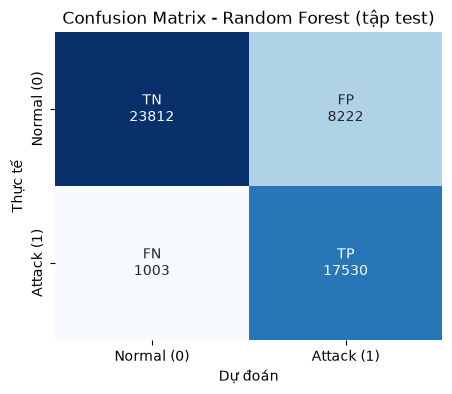

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f'True Negative (Normal đoán đúng):  {tn}')
print(f'False Positive (Normal bị báo là Attack): {fp}')
print(f'False Negative (Attack bị bỏ sót): {fn}')
print(f'True Positive (Attack phát hiện đúng):  {tp}')

annot = [[f'TN\n{tn}', f'FP\n{fp}'], [f'FN\n{fn}', f'TP\n{tp}']]
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'])
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('Confusion Matrix - Random Forest (tập test)')
plt.show()

## Feature importance

Độ quan trọng dựa trên mức giảm Gini impurity (Mean Decrease in Impurity) mà model đo được khi train. Các cột one-hot của cùng một biến (`proto_*`, `service_*`, `state_*`) được **cộng dồn** về biến gốc để so sánh công bằng với các cột số.

Lưu ý: đây là mức độ model *sử dụng* feature để tách dữ liệu train, **không** chứng minh quan hệ nhân quả, và loại importance này có xu hướng ưu tiên các feature có nhiều giá trị khác nhau.

,importance
tcprtt,0.0809
ackdat,0.0762
synack,0.0751
dload,0.0705
dinpkt,0.0639
rate,0.0601
sload,0.0487
dbytes,0.0472
dmean,0.0442
sbytes,0.0439


Top 10 chiếm 61.1% tổng importance


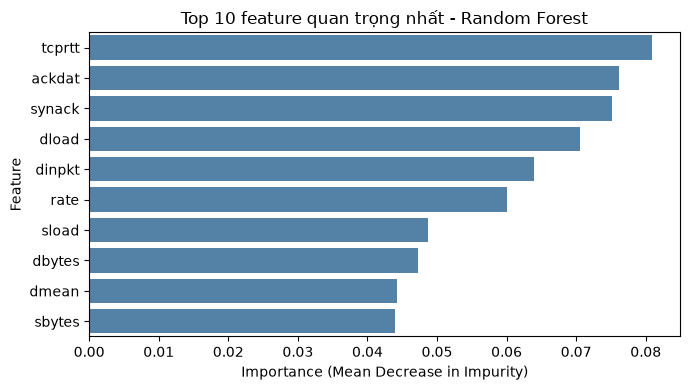

In [7]:
rf = model.named_steps['rf']
encoded_names = model.named_steps['preprocess'].get_feature_names_out()

importance_encoded = pd.Series(rf.feature_importances_, index=encoded_names)

# Cộng dồn các cột one-hot về biến gốc
def original_feature(name):
    for col in categorical_cols:
        if name.startswith(col + '_'):
            return col
    return name

feature_importance = (importance_encoded.groupby(original_feature).sum()
                      .sort_values(ascending=False).rename('importance'))
assert set(feature_importance.index) == set(X_train.columns)  # đúng 31 feature đã làm sạch

top10 = feature_importance.head(10)
display(top10.to_frame().round(4))
print(f'Top 10 chiếm {top10.sum():.1%} tổng importance')

plt.figure(figsize=(7, 4))
sns.barplot(x=top10.values, y=top10.index, color='steelblue')
plt.xlabel('Importance (Mean Decrease in Impurity)')
plt.ylabel('Feature')
plt.title('Top 10 feature quan trọng nhất - Random Forest')
plt.tight_layout()
plt.show()

In [8]:
import json
import joblib

os.makedirs(models_dir, exist_ok=True)
joblib.dump(model, os.path.join(models_dir, 'random_forest.joblib'), compress=3)
feature_importance.to_csv(os.path.join(models_dir, 'random_forest_feature_importance.csv'), header=True)
with open(os.path.join(models_dir, 'random_forest_metrics.json'), 'w', encoding='utf-8') as f:
    json.dump({**{k: round(v, 6) for k, v in metrics.items()},
               'confusion_matrix': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
               'n_train': len(X_train), 'n_test': len(X_test), 'n_features': X_train.shape[1]}, f, indent=2)
print('Đã lưu model, metrics và feature importance vào:', models_dir)

Đã lưu model, metrics và feature importance vào: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\models


## Diễn giải Top 10 feature

**(a) Model đo được:** importance (MDI) từ Random Forest ở trên. **(b) Diễn giải:** giả thuyết vì sao feature hữu ích, dựa trên định nghĩa trong `NUSW-NB15_features.csv` và trung vị (median) trên tập train đã làm sạch. Importance cao chỉ nghĩa là model hay dùng feature đó để tách hai lớp, **không** chứng minh feature đó gây ra hay định nghĩa tấn công.

| # | Feature | (a) Importance | Ý nghĩa | Median Normal → Attack (train) | (b) Vì sao có thể hữu ích |
|---|---|---|---|---|---|
| 1 | `tcprtt` | 0.0809 | Thời gian bắt tay TCP (= `synack` + `ackdat`) | 0.0007 s → 0.104 s | Traffic normal chủ yếu bắt tay rất nhanh (mạng nội bộ testbed); luồng tấn công có RTT cao hơn nhiều. |
| 2 | `ackdat` | 0.0762 | Thời gian từ SYN-ACK đến ACK | 0.0001 s → 0.051 s | Thành phần phía client của RTT, tách hai lớp theo cùng cách với `tcprtt`. |
| 3 | `synack` | 0.0751 | Thời gian từ SYN đến SYN-ACK | 0.0005 s → 0.052 s | Thành phần phía server của RTT. Ba feature thời gian này tương quan mạnh nên chia nhau importance. |
| 4 | `dload` | 0.0705 | Tốc độ bit/s từ đích về nguồn | 583.784 → 3.916 | Luồng normal thường nhận nhiều dữ liệu phản hồi; ~22% luồng tấn công không có phản hồi (`dload` = 0, so với ~4% ở normal). |
| 5 | `dinpkt` | 0.0639 | Khoảng cách trung bình giữa các gói từ đích (ms) | 1,08 → 66,4 | Phản hồi của luồng tấn công thưa và chậm hơn. |
| 6 | `rate` | 0.0601 | Số gói/giây của luồng | 1.385 → 33,7 | Luồng normal trao đổi dày đặc; nhiều luồng tấn công ngắn, rời rạc (dò quét, gửi exploit). |
| 7 | `sload` | 0.0487 | Tốc độ bit/s từ nguồn đến đích | 431.166 → 13.615 | Cùng xu hướng với `rate`: tải gửi đi của luồng tấn công thấp hơn. |
| 8 | `dbytes` | 0.0472 | Số byte từ đích về nguồn | 1.644 → 354 | Phản hồi ít hoặc không có (~22% bằng 0) là dấu hiệu của thăm dò hoặc tấn công không được đáp lại. |
| 9 | `dmean` | 0.0442 | Kích thước trung bình gói từ đích | 91 → 45 | Phản hồi của tấn công thường là gói nhỏ (ACK, RST, thông báo lỗi) thay vì dữ liệu thật. |
| 10 | `sbytes` | 0.0439 | Số byte từ nguồn đến đích | 1.548 → 870 | Payload tấn công thường có kích thước đặc trưng theo từng công cụ, khác với phân bố của traffic normal. |

**Hạn chế:**
- MDI thiên vị các feature liên tục có nhiều giá trị khác nhau.
- Các feature tương quan (`tcprtt`/`synack`/`ackdat`, `sload`/`rate`) chia sẻ importance với nhau.
- Việc normal có RTT rất nhỏ có thể là đặc điểm riêng của môi trường testbed UNSW-NB15, chưa chắc tổng quát được sang mạng 5G thực tế.